In [ ]:
#The usual preamble
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from keras import layers
import time

import tensorflow as tf
from scipy import signal

#for your homework
np.random.seed(10327798)
tf.random.set_seed(10327798)

In [ ]:
BATCH_SIZE = 16

In [ ]:
def make_generator_model(n_inputs):
    model = tf.keras.Sequential()
    model.add(layers.Dense(40, input_shape=(n_inputs,), activation='relu'))
    model.add(layers.GaussianNoise(0.1))
    model.add(layers.Dense(40, activation='relu'))
    model.add(layers.Dense(40, activation='relu'))
    model.add(layers.Dense(n_inputs))

    return model

In [ ]:
#now, make the generator using the function we just created
nInputs = 2
generator = make_generator_model(nInputs)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
def make_discriminator_model(n_inputs):
    model = tf.keras.Sequential()
    model.add(layers.Dense(40, input_shape=(n_inputs,), activation='relu'))
    model.add(layers.Dense(40, activation='relu'))
    model.add(layers.Dense(1))  #output can be -\infty .. \infty
        #if we wanted the output to be in 0..1 could add a sigmoid nonlinearity

    return model

In [ ]:
discriminator = make_discriminator_model(nInputs)

In [ ]:
# This method returns a helper function to compute cross entropy loss
#  It creates a function cross_entropy(y_true, y_predicted)
#  when logits=True is set, y_predicted is in -\infty .. \infty, otherwise in 0..1
#  y_true is always in 0..1
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [ ]:
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)  #how often does it correctly identify a real data point
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)  #how often does it correctly reject a fake data point
    total_loss = real_loss + fake_loss
    return total_loss

In [ ]:
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)  #how often does the discriminator think a fake point is true(1)

In [ ]:
generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [ ]:
# Notice the use of `tf.function`
# This annotation causes the function to be "compiled".
# here we are not creating a sub-class.  This is a toplevel function.
@tf.function
def train_step(real_data):
    noise = tf.random.normal([BATCH_SIZE, nInputs])  #random input for this step

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:   #tapes will watch all the trainable variables
      generated_data = generator(noise, training=True)   #this is the generator prediction

      real_output = discriminator(real_data, training=True)   #discriminator outputs on the real data, hopefully mostly 1
      fake_output = discriminator(generated_data, training=True)  #discriminator outputs on the fake data; discriminator wants these to be 0, generator wants these to be 1

      gen_loss = generator_loss(fake_output)  #how different is discriminator(fake_data) from 1's
      disc_loss = discriminator_loss(real_output, fake_output)  #how well does discriminator discriminate

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)  #find the gradients based on the relative changes in the variables
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))  #gradient descent on the weights
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

In [ ]:
#This is the actual training step.  Each epoch generates a series of batches.
def train(dataset, epochs):
  for epoch in range(epochs):
    start = time.time()

    for iData in range(len(dataset)):
      data_batch = dataset[iData:iData+BATCH_SIZE,:]  #batches are overlapping
      train_step(data_batch)   #train one mini-batch

    print ('Time for epoch {} is {} sec'.format(epoch + 1, time.time()-start))



Text(0.5, 1.0, 'Real Dataset')

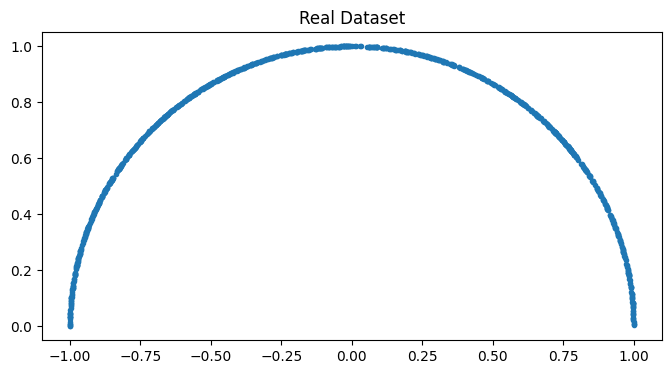

In [ ]:
from numpy.random import default_rng
from numpy import linalg as LA

rng = default_rng()
npoints = 1000
theta = np.pi * rng.random(npoints)  #original data are one dimensional
data_x = np.cos(theta).reshape(npoints,1)  #embed them in a two dimensional space along a half-circle
data_y = np.sin(theta).reshape(npoints,1)
halfcircle_data = np.hstack([data_x,data_y])  #x,y coordinates of each point
plt.figure(figsize=(8,4))
plt.plot(data_x,data_y,'.');
plt.title('Real Dataset')

In [ ]:
#see how well the generator produced points near the set of training points
def show_result():
  generator_input = rng.random(halfcircle_data.shape)
  fake_data = generator(generator_input)
  fake_data_discrim = discriminator(fake_data)
  plt.figure(figsize=(8,4))
  plt.plot(halfcircle_data[:,0], halfcircle_data[:,1],'r.');
  plt.plot(fake_data[:,0], fake_data[:,1],'b.');
  plt.title('Generator output')
  return fake_data

In [ ]:
#see how well the discrimninator performs
def show_test_points(fake_data):
  ntestpoints = 5000
  test_points = np.concatenate((2*rng.random((ntestpoints,1))-1,1.3*rng.random((ntestpoints,1))),axis=1)
  fake_points = fake_data.numpy()
  test_discrim = discriminator(test_points).numpy().reshape(ntestpoints,)
  pos_points = test_points[test_discrim>0,:]
  neg_points = test_points[test_discrim<0,:]
  test_discrim1 = discriminator(fake_points).numpy().reshape(npoints,)
  pos_points1 = fake_points[test_discrim1>0,:]
  neg_points1 = fake_points[test_discrim1<0,:]

  plt.figure(figsize=(8,6))
  plt.plot(halfcircle_data[:,0], halfcircle_data[:,1],'y.');
  plt.plot(fake_data[:,0], fake_data[:,1],'g.');
  plt.plot(neg_points[:,0],neg_points[:,1], 'r.');
  plt.plot(pos_points[:,0],pos_points[:,1], 'b.');
  plt.title('Discriminator pos/neg regions')

  plt.figure(figsize=(8,6))
  plt.plot(halfcircle_data[:,0], halfcircle_data[:,1],'y.');
  plt.plot(pos_points1[:,0],pos_points1[:,1], 'bo');
  plt.plot(neg_points1[:,0],neg_points1[:,1], 'ro');
  plt.title('Discriminator performance on fake data')



Time for epoch 1 is 17.35900902748108 sec
Time for epoch 2 is 6.730719327926636 sec
Time for epoch 3 is 5.125927925109863 sec
Time for epoch 4 is 3.702660083770752 sec
Time for epoch 1 is 5.01357626914978 sec
Time for epoch 2 is 4.201746463775635 sec
Time for epoch 3 is 3.6312217712402344 sec
Time for epoch 4 is 3.6393065452575684 sec
Time for epoch 1 is 4.175893068313599 sec
Time for epoch 2 is 3.6043460369110107 sec
Time for epoch 3 is 3.6471545696258545 sec
Time for epoch 4 is 4.038234710693359 sec
Time for epoch 1 is 3.7159035205841064 sec
Time for epoch 2 is 3.567905902862549 sec
Time for epoch 3 is 3.7469475269317627 sec
Time for epoch 4 is 3.998203992843628 sec
Time for epoch 1 is 3.568763256072998 sec
Time for epoch 2 is 3.6002068519592285 sec
Time for epoch 3 is 4.510977268218994 sec
Time for epoch 4 is 4.2625572681427 sec


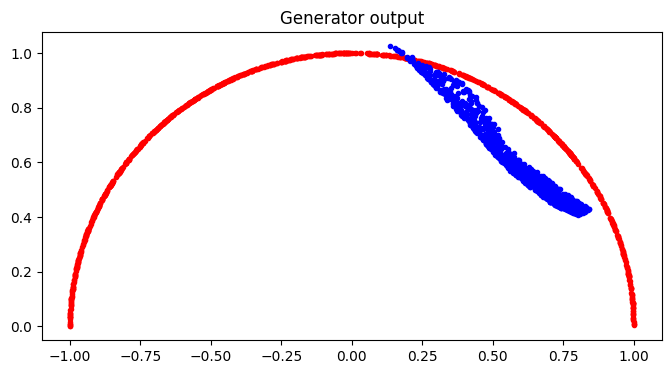

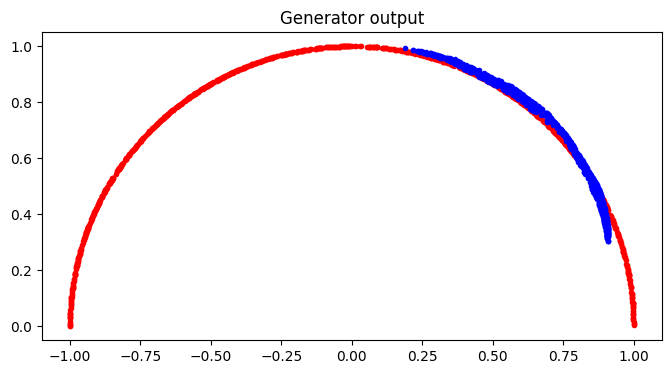

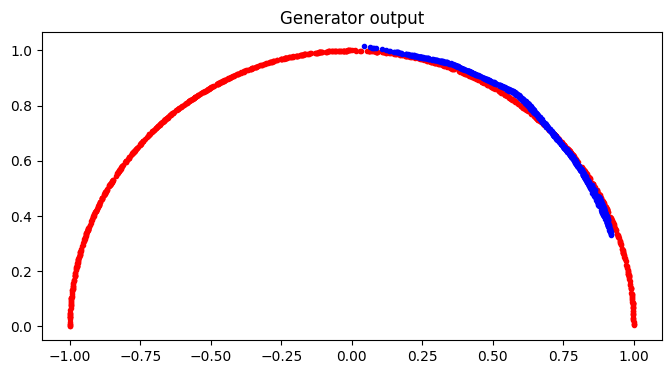

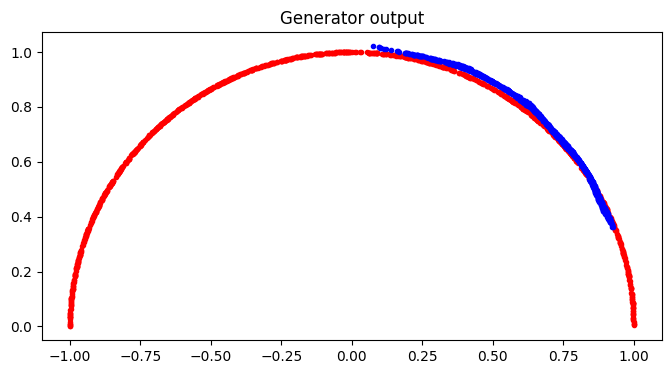

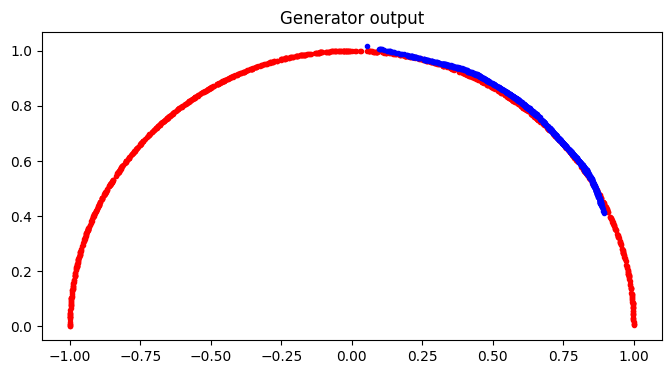

In [ ]:
#The Training!
EPOCHS = 4
repeat = 5
for n in range(repeat):
  train(halfcircle_data, EPOCHS)
  show_result()


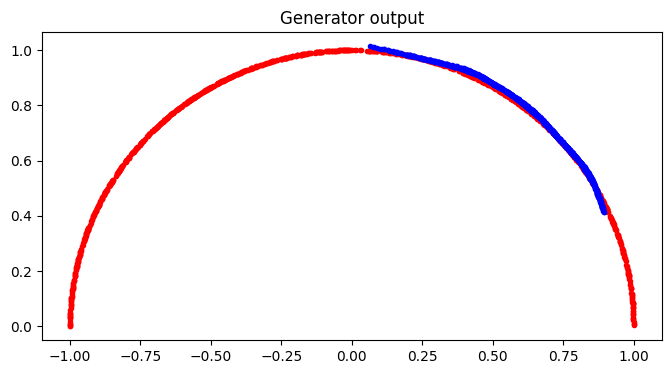

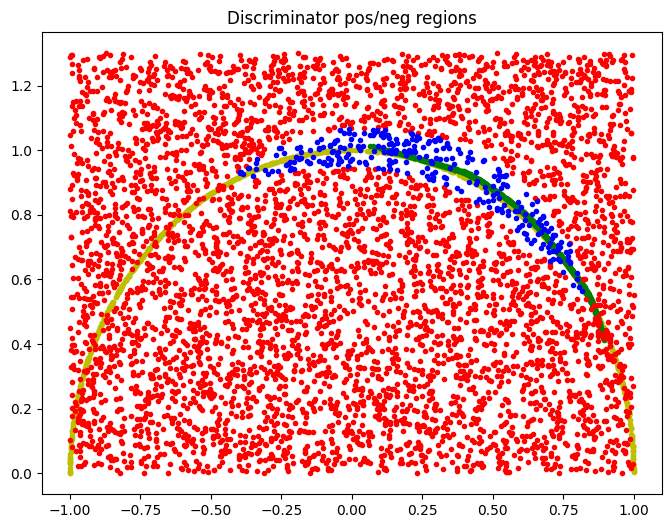

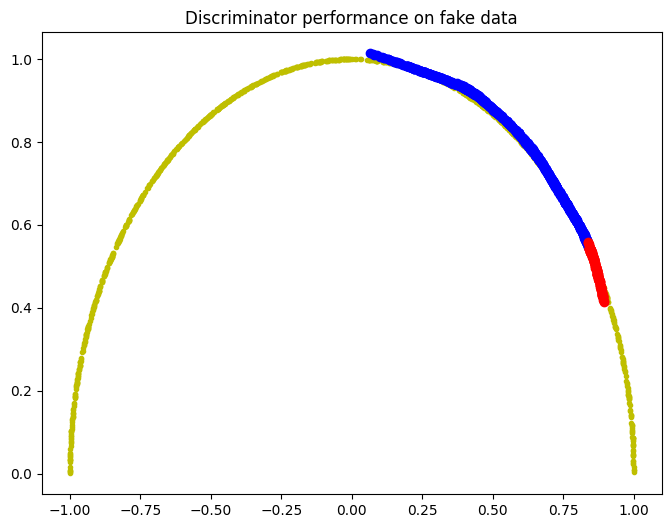

In [ ]:
  #now show the results for the generator and discriminator performance
  fake_data = show_result();
  show_test_points(fake_data);

In [ ]:
# the usual
import numpy as np
import scipy as sp
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
#1D version
npoints = 100  #the number of different possible values of the random variable
ntimes = 100   #the maximum time point
nparallel = 50000  #run all the random walks at the same time

#create the true distribution p(x) as a sum of two gaussians
x = np.linspace(-1,1,npoints)
sigma = 0.1
p = np.exp(-(x-0.5)**2/(2*sigma**2)) + np.exp(-(x+0.5)**2/(2*sigma**2))
p = p/sum(p)

rng = np.random.default_rng()
save_trace = np.zeros((nparallel,ntimes))  #one row for each random walk

x1 = x[rng.choice(npoints,(nparallel,1),p=p)]
for t in range(ntimes):
  x1 += 0.1*rng.standard_normal((nparallel,1))
  x1[x1>1] = 1   #bounded region.
  x1[x1<-1] = -1
  save_trace[:,t] = x1.reshape(nparallel,)   #where each walk was at this timestep




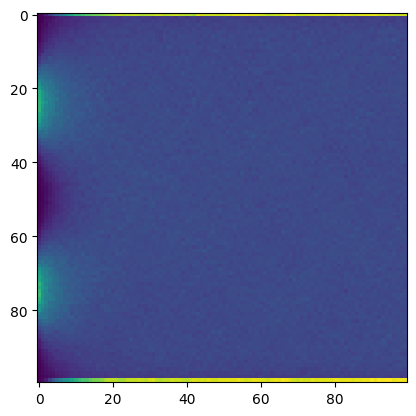

In [ ]:
save_hist = np.zeros((npoints, ntimes))
for t in range(ntimes):
  save_hist[:,t], bin_edges = np.histogram(save_trace[:,t], bins=np.linspace(-1,1,npoints+1))
  #histogram operation converts the random walk values into a probability density
plt.figure()
plt.imshow(save_hist)
plt.show()
#result is the probability density of locations at each time point.

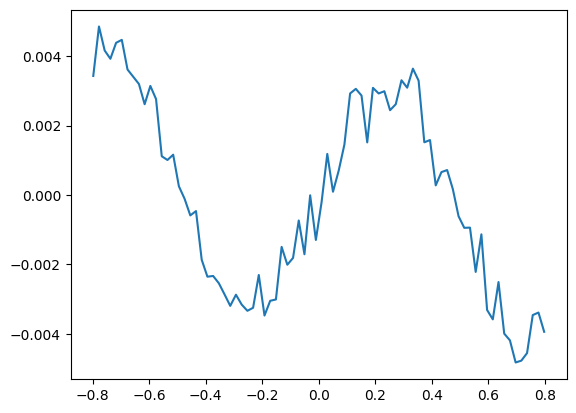

In [ ]:
vecfield = np.zeros((npoints,1))

v = save_trace[:,1:-1] - save_trace[:,2:]  #how much each of the 50,000 random walks moved
idx = npoints * (save_trace[:,2:] + 1)/2   #where was each random walk?
idx = idx.astype(int)
for val in range(npoints):
  vecfield[val] = np.mean(v[idx==val])   #how much did each move as a function of where it was?

plt.figure()
plt.plot(x[10:-10],vecfield[10:-10])  #ignore the edges
plt.show()



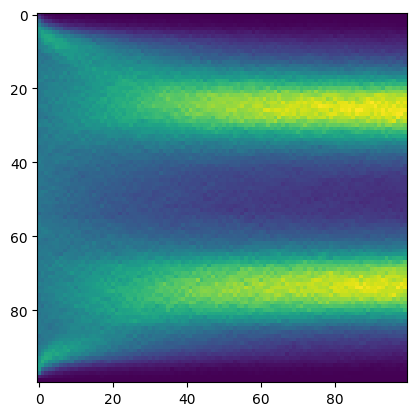

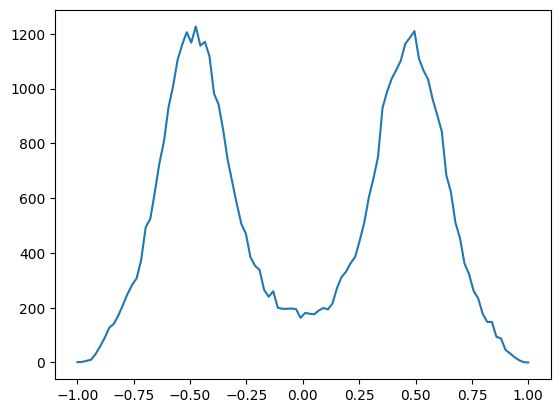

In [ ]:
randvals = -1.0 + 2.0*rng.uniform(size=(nparallel,1))  #start with a set of random values
save_rvals = np.zeros((nparallel,ntimes))
save_rhist = np.zeros((npoints, ntimes))

for t in range(ntimes):
  randvidx = npoints * (randvals + 1)/2   #convert to indexes
  randvidx = randvidx.astype(int)
  for val in range(npoints):
    randvals[randvidx == val] += vecfield[val]  #add the appropriate vector direction based on the current location
    randvals += 0.003*rng.standard_normal((nparallel,1))  #some noise
    randvals[randvals>1] = 1    #keep it bounded
    randvals[randvals<-1] = -1
  save_rvals[:,t] = randvals.reshape(nparallel,)
  save_rhist[:,t], bin_edges = np.histogram(save_rvals[:,t], bins=np.linspace(-1,1,npoints+1))  #probability at each time.


plt.figure()
plt.imshow(save_rhist)  #what happens over time
plt.show()

plt.figure()
plt.plot(x,save_rhist[:,t])  #the final time
plt.show()

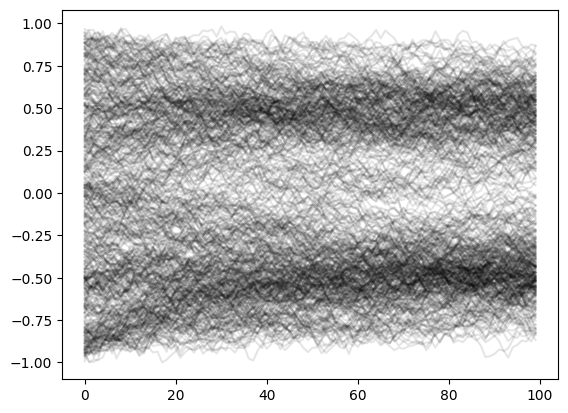

In [ ]:
plt.figure()
plt.plot(save_rvals[1:500,:].T,'k',alpha=0.1)
plt.show()


In [ ]:
from keras.datasets.mnist import load_data

(trainX, trainy), (testX, testy) = load_data()
trainX = np.float32(trainX) / 255.
testX = np.float32(testX) / 255.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


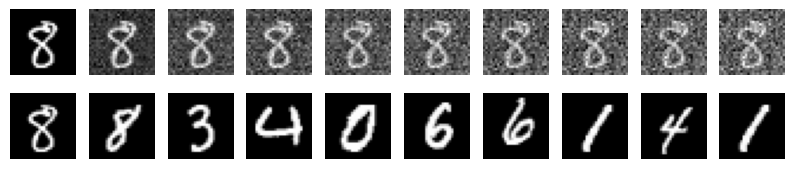

In [ ]:
mimages = 4000
mimage_copies = 10
mimage_originals = int(mimages/mimage_copies)
mnist_data = np.zeros((mimages,28,28))
k=0
iOrig = np.random.randint(100, size=mimage_originals)  #choose a set of random images
for c in range(mimage_copies):    #will create several copies of each image for purposes of training.
  for i in range(mimage_originals):
    mnist_data[k,:,:] = trainX[iOrig[i],:,:]
    k +=1

mtimes = 50
m,h,w = mnist_data.shape

#add noise successively to each image
kforward = np.zeros((m,h,w, mtimes))
kforward[:,:,:,0] = mnist_data
for t in range(mtimes-1):
  kforward[:,:,:,t+1] = kforward[:,:,:,t] + 0.05 * rng.standard_normal((m,h,w))

#training data for reverse diffusion operator
nexamples = 20000
nback = 1  #how many steps back to train x(t) -> x(t-nback)
useProjectionOperator = 1
rand_times = np.random.randint(mtimes-nback, size=nexamples)
rand_images = np.random.randint(m, size=nexamples)
itrainX = kforward[rand_images, :, :, rand_times+nback].reshape((nexamples, h, w, 1))
if useProjectionOperator:
  #train to the clean image (projection operator)
  itrainY = kforward[rand_images, :, :, 0].reshape((nexamples, h, w, 1))  #alternate option for training x(t) -> x(0)
else:
  #diffusion operator
  itrainY = kforward[rand_images, :, :, rand_times].reshape((nexamples, h, w, 1))  #x(t) -> x(t-nback)


#show examples of successively adding noise, plus some of the original images
plt.figure(figsize = (10,2))
for i in range(10):
  ax = plt.subplot(2,10,i+1)
  plt.imshow(kforward[0,:,:,i*5])
  plt.gray()
  ax.set_axis_off()
  ax = plt.subplot(2,10,i+11)
  #plt.imshow(kforward[1,:,:,i*10])
  plt.imshow(mnist_data[i,:,:])
  plt.gray()
  ax.set_axis_off()
plt.show()


In [ ]:
#Use an autoencoder structure to learn the reverse diffusion
import tensorflow.keras as keras    #front-end API to access tensorflow
from keras.layers import Conv2D, MaxPooling2D, UpSampling2D, Flatten, Dense, Reshape
from keras import Model, Input
from tensorflow.keras.utils import plot_model

opt = keras.optimizers.Adam(learning_rate=0.002)
nhidden = 32

#Smaller nonlinear encoding/decoding network.
input_img = keras.Input(shape=(28, 28, 1))

x = Conv2D(nhidden, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(nhidden, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Flatten()(x)
x = Dense(nhidden*10, activation='relu')(x)
encoded = x

# At this point the representation is (7, 7, 32)
x = encoded
x = Dense(nhidden*7*7, activation='relu')(x)
x = Reshape((7, 7, nhidden))(x)
x = Conv2D(nhidden, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
x = Conv2D(nhidden, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(1, (3, 3), activation='linear', padding='same')(x)

autoencoder = keras.Model(input_img, decoded)
autoencoder.compile(optimizer=opt, loss='mse')  #bce loss because we have a sigmoid at the output

autoencoder.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 320)            │       502,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1568)           │       503,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,033,761 (3.94 MB)

 Trainable params: 1,033,761 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.0339
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0043
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0028


<Axes: >

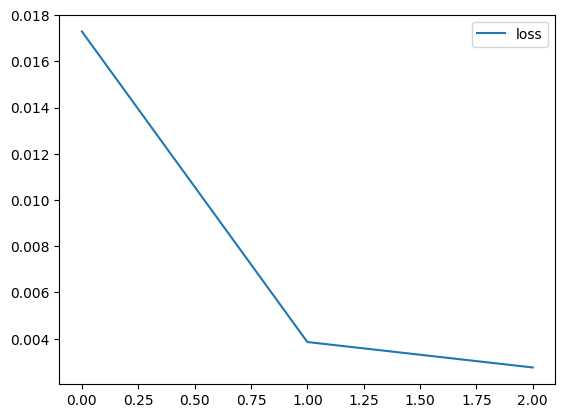

In [ ]:
#this time, train the network explicitly to remove noise
autoencoder.fit(itrainX, itrainY,
                epochs=3, verbose = 1,
                batch_size=64,
                shuffle=True)

losses = pd.DataFrame(autoencoder.history.history)
losses.plot()


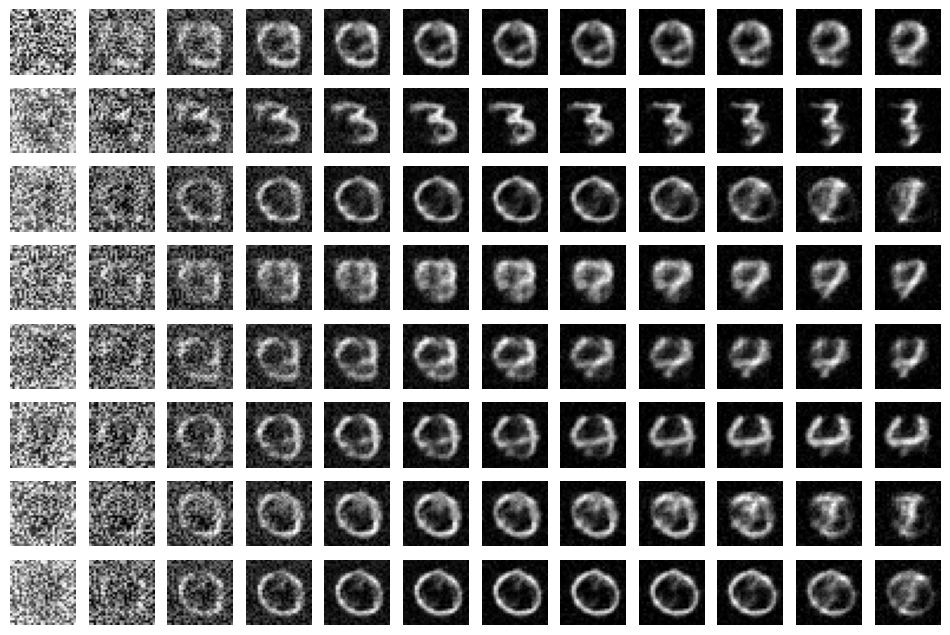

In [ ]:
ncount = 8  #number of different examples
nsteps = 12  #reverse diffusion steps for each sample
plt.figure(figsize=(nsteps,ncount))
pnum = 1
ri_total = np.zeros((1,28,28,1))
for i in range(ncount):
  #choose a random starting image
  rand_img = rng.uniform(size=(1,28,28,1)) - ri_total  /(i+.0001)
  for rep in range(nsteps):
    ax = plt.subplot(ncount,nsteps,pnum)
    pnum += 1
    plt.imshow(rand_img.reshape(28,28))
    plt.gray()
    ax.set_axis_off()

    #predict the previous image in the sequence
    rand_img2 = autoencoder.predict(rand_img,verbose=0)
    rand_img2 = 0.5 * rand_img + 0.5* rand_img2  #average (this makes a better integrator)
    rand_img = rand_img2 + 0.01 * rng.standard_normal((1,28,28,1))  #some noise will help
    rand_img[rand_img>1] = 1
    rand_img[rand_img<0] = 0

  ri_total+=rand_img

plt.show()


